# MEAI502 · Lab 3 · Logistic Regression
**Applied Machine Learning · Dr. Naila Marir · Effat University** · ⏱ 150 minutes

We build a model that predicts whether a tumour is **malignant (1)** or **benign (0)**, step by step, exactly as in the lecture.

### How every activity works
| | |
|---|---|
| 🎯 | **What you will learn** |
| ▶️ | **Run this** — code already written. Just run it (`Shift + Enter`). |
| ✏️ | **Your turn** — replace `...` with **one short line**. The hint is right above. |
| ✅ | **Check** — prints *Correct!* or tells you what to fix. |
| 💬 | **Question** — answer in one or two sentences. |

### The 5 activities
| # | Activity | Time | Your turn |
|---|---|---|---|
| 1 | Look at the data | 20 min | TODO 1 |
| 2 | Sigmoid and prediction | 25 min | TODO 2, 3 |
| 3 | Decision boundary | 25 min | TODO 4 |
| 4 | Cost and gradient descent | 40 min | TODO 5, 6 |
| 5 | Train and evaluate a real model | 40 min | TODO 7 |

> ⚠️ For education only. This is not a medical diagnostic tool.

## ▶️ Setup — run this once
This cell loads the tools and some ready-made **helper functions** for plots and checks. You do not need to read it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
plt.rcParams["figure.figsize"] = (6, 4.5)
plt.rcParams["axes.grid"] = True

# ---------- helper functions (ready-made) ----------
def check(test, ok, hint):
    """Prints Correct! if test() is True, otherwise a hint."""
    try:
        passed = bool(test())
    except Exception:
        passed = False
    print("✅ Correct! " + ok if passed else "❌ Not yet. " + hint)

def plot_data(X2, y, labels=("mean radius", "mean texture")):
    plt.scatter(X2[y == 0, 0], X2[y == 0, 1], marker="o", facecolors="none", edgecolors="tab:blue", label="benign (0)")
    plt.scatter(X2[y == 1, 0], X2[y == 1, 1], marker="x", color="tab:red", label="malignant (1)")
    plt.xlabel(labels[0]); plt.ylabel(labels[1]); plt.legend(); plt.show()

def plot_boundary(theta, X2=None, y=None, lim=(-0.5, 4.5), labels=("x1", "x2"), title=""):
    g = np.linspace(lim[0], lim[1], 300)
    G1, G2 = np.meshgrid(g, g)
    P = 1 / (1 + np.exp(-(theta[0] + theta[1] * G1 + theta[2] * G2)))
    plt.contourf(G1, G2, P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.35)
    plt.contour(G1, G2, P, levels=[0.5], colors="green", linewidths=3)
    if X2 is not None:
        plt.scatter(X2[y == 0, 0], X2[y == 0, 1], marker="o", facecolors="none", edgecolors="tab:blue", label="benign (0)")
        plt.scatter(X2[y == 1, 0], X2[y == 1, 1], marker="x", color="tab:red", label="malignant (1)")
        plt.legend(loc="upper left")
    plt.xlim(lim); plt.ylim(lim); plt.xlabel(labels[0]); plt.ylabel(labels[1]); plt.title(title); plt.show()

def add_ones(X):
    """Adds the column x0 = 1 in front, like in the lecture."""
    return np.c_[np.ones(len(X)), X]

def plot_loss(histories):
    for name, h in histories.items():
        plt.plot(h, lw=2.5, label=name)
    plt.xlabel("iteration"); plt.ylabel("cost J(θ)"); plt.title("Learning curves"); plt.legend(); plt.show()

print("Ready ✅")

Ready ✅


---
# Activity 1 · Look at the data ⏱ 20 min
🎯 **What you will learn:** what the features `X` and the labels `y` look like.

▶️ **Run this.** We load 569 tumours. `X` has 30 measurements per tumour. `y` is **1 = malignant**, **0 = benign**.

In [2]:
data = load_breast_cancer()
X = data.data
y = (data.target_names[data.target] == "malignant").astype(int)   # 1 = malignant, 0 = benign

print("X shape:", X.shape)      # (tumours, features)
print("y shape:", y.shape)
pd.DataFrame(X[:5, :3], columns=data.feature_names[:3]).assign(y=y[:5])

X shape: (569, 30)
y shape: (569,)


,mean radius,mean texture,mean perimeter,y
0,17.99,10.38,122.80,1
1,20.57,17.77,132.90,1
2,19.69,21.25,130.00,1
3,11.42,20.38,77.58,1
4,20.29,14.34,135.10,1


✏️ **Your turn · TODO 1:** count the malignant tumours.
*Hint:* `y` contains only 0s and 1s, so the **sum** of `y` is the number of 1s → `y.sum()`

In [3]:
n_malignant = y.sum()               # TODO 1
n_benign = len(y) - n_malignant
print("Malignant:", n_malignant, " Benign:", n_benign)

Malignant: 212  Benign: 357


In [4]:
# ✅ Check
check(lambda: n_malignant == 212, "There are 212 malignant and 357 benign tumours.", "Use y.sum().")

✅ Correct! There are 212 malignant and 357 benign tumours.


▶️ **Run this.** We keep two features we can draw: **mean radius** and **mean texture**.

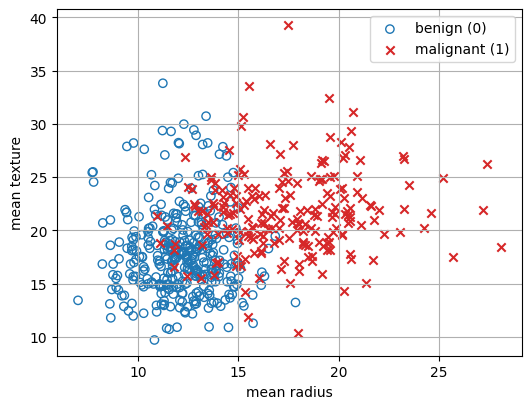

In [5]:
X2 = X[:, [0, 1]]        # column 0 = mean radius, column 1 = mean texture
plot_data(X2, y)

### 💬 Question 1
Looking at the plot, which feature separates malignant from benign better: **radius** or **texture**?

✍️ *Your answer:*
I believe mean radius separates the two classes better because malignant tumours generally have a larger mean radius than benign tumours, although there is some overlap.

---
# Activity 2 · Sigmoid and prediction ⏱ 25 min
🎯 **What you will learn:** turn a score $z$ into a probability, then into a class 0 or 1.

$$g(z) = \frac{1}{1 + e^{-z}}$$

✏️ **Your turn · TODO 2:** write the sigmoid. *Hint:* `np.exp(-z)` computes $e^{-z}$.

In [6]:
def sigmoid(z):
    return (1/(1+np.exp(-z)))             # TODO 2

In [7]:
# ✅ Check
check(lambda: abs(sigmoid(0) - 0.5) < 1e-9 and sigmoid(10) > 0.99,
      "sigmoid(0) = 0.5 and large z gives almost 1.", "Use 1 / (1 + np.exp(-z)).")

✅ Correct! sigmoid(0) = 0.5 and large z gives almost 1.


▶️ **Run this** to see your sigmoid.

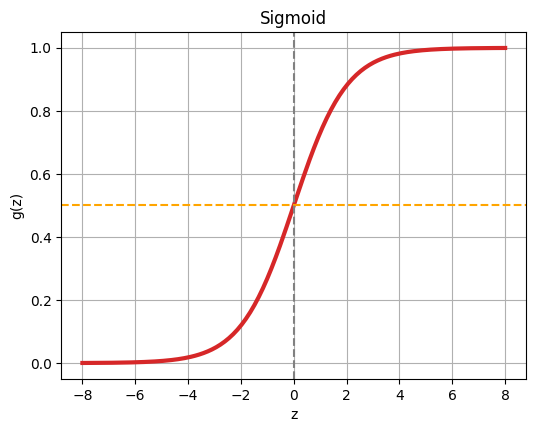

In [8]:
z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z), color="tab:red", lw=3)
plt.axhline(0.5, ls="--", color="orange"); plt.axvline(0, ls="--", color="gray")
plt.xlabel("z"); plt.ylabel("g(z)"); plt.title("Sigmoid"); plt.show()

✏️ **Your turn · TODO 3:** turn probabilities into classes: **1 if probability ≥ 0.5**, else 0.
*Hint:* `(probability >= threshold)` gives True/False; `.astype(int)` turns it into 1/0.

In [9]:
def predict_class(probability, threshold=0.5):
    return (probability>=threshold).astype(int)                                  # TODO 3

print(predict_class(np.array([0.15, 0.40, 0.50, 0.73, 0.95])))

[0 0 1 1 1]


In [10]:
# ✅ Check
check(lambda: list(predict_class(np.array([0.15, 0.40, 0.50, 0.73, 0.95]))) == [0, 0, 1, 1, 1],
      "You get [0 0 1 1 1].", "Use (probability >= threshold).astype(int).")

✅ Correct! You get [0 0 1 1 1].


### 💬 Question 2
Why does $z = 0$ give a probability of exactly 0.5?

✍️ *Your answer:*
When z = 0, the e will be raised to power 0. Since e⁰ = 1, the result is 1 / 2 = 0.5. This means the model gives an equal probability to both classes.

---
# Activity 3 · Decision boundary ⏱ 25 min
🎯 **What you will learn:** compute $z = X\theta$ for many points at once and see the boundary.

▶️ **Run this.** Like the lecture: $\theta = [-3, 1, 1]$. We add the column $x_0 = 1$ with `add_ones`.

In [11]:
theta = np.array([-3, 1, 1])
points = np.array([[1, 1],      # patient A
                   [2, 3]])     # patient B
Xb = add_ones(points)           # each row becomes [1, x1, x2]
Xb

array([[1., 1., 1.],
       [1., 2., 3.]])

✏️ **Your turn · TODO 4:** compute the scores of both patients **in one line**.
*Hint:* matrix times vector in NumPy is `@` → `Xb @ theta`

In [12]:
z = Xb @ theta                         # TODO 4
print("z =", z)
print("probabilities =", sigmoid(z).round(3))
print("classes =", predict_class(sigmoid(z)))

z = [-1.  2.]
probabilities = [0.269 0.881]
classes = [0 1]


✅ Correct! A: z = -1 → class 0.  B: z = 2 → class 1.


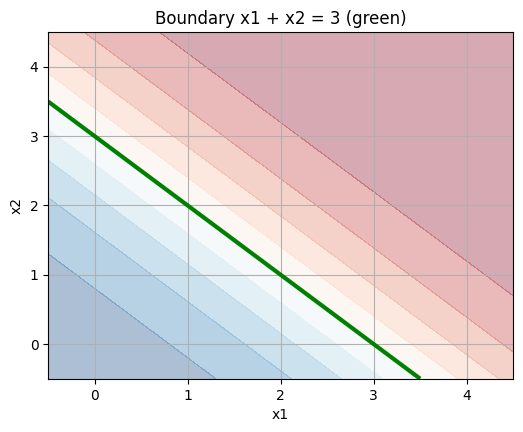

In [13]:
# ✅ Check
check(lambda: list(z) == [-1, 2], "A: z = -1 → class 0.  B: z = 2 → class 1.", "Use Xb @ theta.")
plot_boundary(theta, title="Boundary x1 + x2 = 3 (green)")

▶️ **Run this.** Now scikit-learn **learns** θ from the real data (radius and texture, **standardized** first).
`intercept_` is θ₀, `coef_` holds θ₁ and θ₂.

learned θ = [-0.69  3.26  0.87]


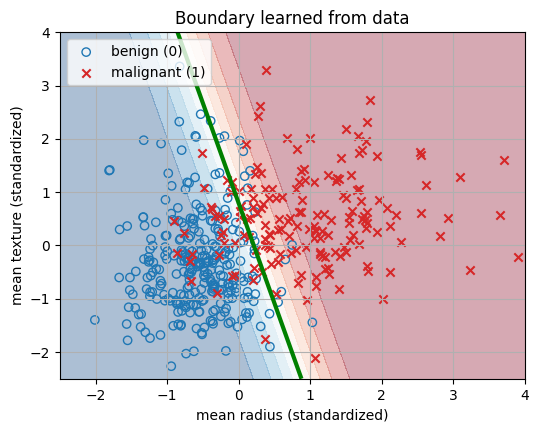

In [14]:
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X2_train)          # learn mean and std from training data only
X2_train_s = scaler.transform(X2_train)

clf = LogisticRegression().fit(X2_train_s, y2_train)
theta_learned = np.r_[clf.intercept_, clf.coef_.ravel()]
print("learned θ =", theta_learned.round(2))
plot_boundary(theta_learned, X2_train_s, y2_train, lim=(-2.5, 4),
              labels=("mean radius (standardized)", "mean texture (standardized)"), title="Boundary learned from data")

### 💬 Question 3
Which feature got the **bigger weight** in the learned θ? What does that tell you?

✍️ *Your answer:* Mean radius has the bigger weight because its coefficient is 3.26, compared to 0.87 for mean texture. This tells us that mean radius has a stronger influence on the model's prediction.

---
# Activity 4 · Cost and gradient descent ⏱ 40 min
🎯 **What you will learn:** measure the error with the cost $J(\theta)$, then **learn θ yourself** with gradient descent.

$$J(\theta) = -\frac{1}{m}\sum\Big[y\log p + (1-y)\log(1-p)\Big], \qquad p = g(X\theta)$$

✏️ **Your turn · TODO 5:** complete the cost.
*Hint:* `np.mean(...)` does the $\frac1m\sum$. Write: `-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))`

In [15]:
def cost(Xb, y, theta):
    p = sigmoid(Xb @ theta)
    p = np.clip(p, 1e-15, 1 - 1e-15)      # avoids log(0)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))               # TODO 5

In [16]:
# ✅ Check (with θ = 0 every probability is 0.5, so J = log 2 ≈ 0.693)
Xb_train = add_ones(X2_train_s)
check(lambda: abs(cost(Xb_train, y2_train, np.zeros(3)) - 0.6931) < 1e-3,
      "J(θ = 0) = 0.693.", "Check the signs and use np.mean.")

✅ Correct! J(θ = 0) = 0.693.


✏️ **Your turn · TODO 6:** complete **one gradient descent step** (2 lines).

$$\text{gradient} = \frac{1}{m}X^T(p - y), \qquad \theta := \theta - \alpha \cdot \text{gradient}$$

*Hint:* `Xb.T @ (p - y) / m` and `theta - alpha * gradient`

In [17]:
def gradient_descent(Xb, y, alpha=0.1, iterations=300):
    m = len(y)
    theta = np.zeros(Xb.shape[1])
    history = []
    for i in range(iterations):
        p = sigmoid(Xb @ theta)
        gradient = Xb.T @ (p - y) / m                   # TODO 6a
        theta = theta - alpha * gradient                # TODO 6b
        history.append(cost(Xb, y, theta))
    return theta, history

▶️ **Run this.** Train with two learning rates and compare.

α = 0.1 → θ = [-0.66  2.44  0.78]  final J = 0.272
α = 1.0 → θ = [-0.7   3.68  0.94]  final J = 0.256


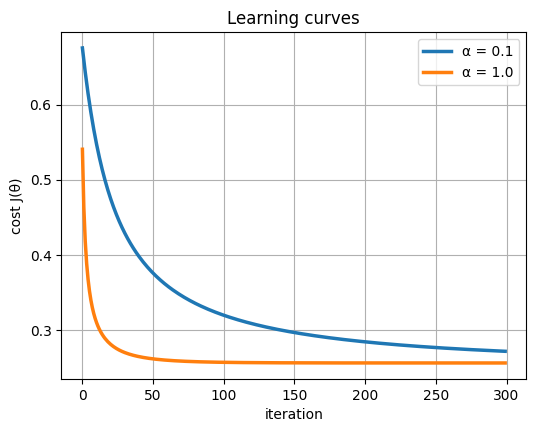

✅ Correct! The cost goes down: your model is learning!


In [18]:
theta_a, hist_a = gradient_descent(Xb_train, y2_train, alpha=0.1)
theta_b, hist_b = gradient_descent(Xb_train, y2_train, alpha=1.0)
print("α = 0.1 → θ =", theta_a.round(2), " final J =", round(hist_a[-1], 3))
print("α = 1.0 → θ =", theta_b.round(2), " final J =", round(hist_b[-1], 3))
plot_loss({"α = 0.1": hist_a, "α = 1.0": hist_b})

# ✅ Check
check(lambda: hist_b[-1] < 0.26 and hist_b[-1] < hist_b[0],
      "The cost goes down: your model is learning!", "Check TODO 6: theta - alpha * gradient (minus sign).")

### 💬 Question 4
Which learning rate reached a low cost faster? Look at the two curves.

✍️ *Your answer:* I think alpha = 1.0 reached a low cost faster because its learning curve decreases more quickly.

---
# Activity 5 · Train and evaluate a real model ⏱ 40 min
🎯 **What you will learn:** train on **all 30 features**, read the confusion matrix, compute precision and recall, and choose a threshold.

▶️ **Run this.** A **pipeline** scales the data and trains the model in one object (no data leakage).

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:, 1]    # probability of malignant
y_pred = model.predict(X_test)                # class, threshold 0.5
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 3))

Test accuracy: 0.965


▶️ **Run this.** scikit-learn puts class 0 first: the matrix is `[[TN, FP], [FN, TP]]`.

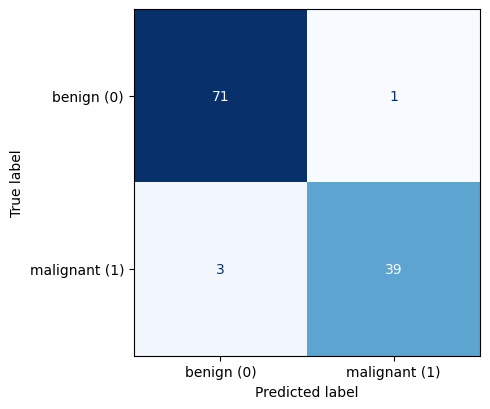

TP = 39  FN = 3  FP = 1  TN = 71


In [20]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["benign (0)", "malignant (1)"]).plot(cmap="Blues", colorbar=False)
plt.grid(False); plt.show()
tn, fp, fn, tp = cm.ravel()
print("TP =", tp, " FN =", fn, " FP =", fp, " TN =", tn)

✏️ **Your turn · TODO 7:** compute precision and recall from the four numbers.

$$\text{precision} = \frac{TP}{TP + FP} \qquad \text{recall} = \frac{TP}{TP + FN}$$

In [21]:
precision = (tp/(tp+fp))            # TODO 7a round(precision_score(y_test,y_pred))
recall = (tp/(tp+fn))               # TODO 7b  round(recall_score(y_test,y_pred))
print("precision =", round(precision, 3), " recall =", round(recall, 3))

precision = 0.975  recall = 0.929


In [22]:
# ✅ Check
check(lambda: np.isclose(precision, precision_score(y_test, y_pred)) and np.isclose(recall, recall_score(y_test, y_pred)),
      "Your numbers match scikit-learn.", "precision = tp / (tp + fp), recall = tp / (tp + fn).")

✅ Correct! Your numbers match scikit-learn.


▶️ **Run this.** Compare three thresholds. We use a **validation set** (taken from the training data), so the test set stays untouched.

In [23]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0, stratify=y_train)
p_val = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr).predict_proba(X_val)[:, 1]

rows = []
for t in [0.3, 0.5, 0.7]:
    pred = predict_class(p_val, threshold=t)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_val, pred).ravel()
    rows.append({"threshold": t, "accuracy": accuracy_score(y_val, pred),
                 "recall": recall_score(y_val, pred), "precision": precision_score(y_val, pred),
                 "missed malignant (FN)": fn_, "false alarms (FP)": fp_})
pd.DataFrame(rows).round(3)

,threshold,accuracy,recall,precision,missed malignant (FN),false alarms (FP)
0,0.3,0.974,0.977,0.955,1,2
1,0.5,0.974,0.953,0.976,2,1
2,0.7,0.974,0.930,1.000,3,0


▶️ **Run this.** The ROC curve shows all thresholds at once.

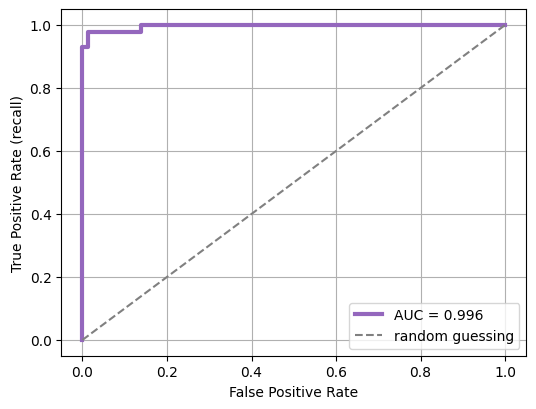

In [24]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, lw=3, color="tab:purple", label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray", label="random guessing")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (recall)"); plt.legend(); plt.show()

### 💬 Question 5
Look at the threshold table. For a **cancer screening** tool, which threshold would you choose, and why?

✍️ *Your answer:* I would choose a threshold of 0.3 because it gives the highest recall of 0.977 and only misses one malignant case. Although it produces two false alarms, I think detecting as many cancer cases as possible is more important for cancer screening.

### 💬 Final question (3–5 sentences)
Would you always choose the model or threshold with the **highest accuracy**? Explain why or why not.

✍️ *Your answer:* No, I would not always choose the model with the highest accuracy. Sometimes accuracy does not tell us enough about the types of mistakes the model makes. For cancer screening, false negatives can be more dangerous because they mean a malignant tumour was classified as benign. Therefore, recall can be more important than accuracy, and we should choose a threshold that minimizes missed malignant cases.

---
## 📤 Submit
`File → Download → .ipynb` · name it `MEAI502_Lab3_<YourName>.ipynb` · all cells run, all 💬 answers written.

| Activity | What we check | Marks |
|---|---|---|
| 1 · Data | TODO 1 + Question 1 | 2 |
| 2 · Sigmoid | TODO 2, 3 + Question 2 | 2 |
| 3 · Boundary | TODO 4 + Question 3 | 2 |
| 4 · Gradient descent | TODO 5, 6 + Question 4 | 2 |
| 5 · Evaluation | TODO 7 + Question 5 + final question | 2 |
| | **Total** | **10** |